In [412]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import copy
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from scipy.spatial.distance import cdist
from functools import partial

# MLP

In [413]:
class softmax():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        x = x - np.max(x, axis=1, keepdims=True)
        exps = np.exp(x)
        self.out = exps / np.sum(exps, axis=1, keepdims=True)
        return self.out

    def backward(self, grad_output):
        return grad_output

class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)
    
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input
    
class liniowa():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = x
        return self.out

    def backward(self, grad_output):
        return grad_output
    
class tanh():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9
        self.l2_lambda = 0.0

    def forward(self, x):
        self.out = np.tanh(x)
        return self.out

    def backward(self, grad_output):
        # f'(x) = 1 - f(x)^2
        return grad_output * (1 - self.out ** 2)

In [414]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)
    
class Crossentropy:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
        strata = -np.sum(y_true * np.log(y_pred_clipped))
        return strata
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [415]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

        self.l2_lambda = 0.0

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        self.grad_wagi += self.l2_lambda * self.wagi

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [416]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9, l2_lambda=0.0):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        self.l2_lambda = l2_lambda
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik
            warstwa.l2_lambda = self.l2_lambda

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [417]:
def mse(y_true, y_pred):
    if y_true.ndim == 1 and y_pred.ndim == 2:
        liczba_klas = y_pred.shape[1]
        y_true_onehot = np.zeros_like(y_pred)
        y_true_onehot[np.arange(len(y_true)), y_true] = 1
        y_true_do_obliczen = y_true_onehot
    else:
        y_true_do_obliczen = y_true
        
    return np.mean((y_true_do_obliczen - y_pred) ** 2)

In [418]:
def f1(y_true, y_pred):
    if y_true.ndim == 2 and y_true.shape[1] > 1:
        y_true_labels = np.argmax(y_true, axis=1)
    else:
        y_true_labels = y_true.flatten()
        
    y_pred_labels = np.argmax(y_pred, axis=1)
    
    klasy = np.unique(y_true_labels)
    f1_suma = 0
    
    for k in klasy:
        TP = np.sum((y_pred_labels == k) & (y_true_labels == k))
        FP = np.sum((y_pred_labels == k) & (y_true_labels != k))
        FN = np.sum((y_pred_labels != k) & (y_true_labels == k))
        
        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0
        
        if precision + recall > 0:
            f1_k = 2 * (precision * recall) / (precision + recall)
        else:
            f1_k = 0
            
        f1_suma += f1_k
        
    return f1_suma / len(klasy)

In [419]:
def train(X_train, y_train, X_test, y_test, X_val, y_val, model, epoki, rozmiar_batcha, funkcja_straty=MSE, regresja=True, test=False, test_score=False, patience=100):
    # Skalowanie cech X
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    X_val_scaled = (X_val - x_min) / (x_max - x_min)

    # Skalowanie Y tylko jeśli to regresja
    if regresja:
        y_min = y_train.min(axis=0)
        y_max = y_train.max(axis=0)
        y_train_scaled = (y_train - y_min) / (y_max - y_min)
        y_val_scaled = (y_val - y_min) / (y_max - y_min)
    else:
        y_train_scaled = y_train
        y_val_scaled = y_val
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_score_train = []
    hist_score_val = []
    hist_strata_train = []

    najlepsza_strata_val = float('inf')
    brak_poprawy = 0
    najlepszy_model_wagi = None

    for i in tqdm(range(epoki)):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Przejście w przód dla batcha
            y_pred_batch = model.forward(X_batch)
            
            # Strata i gradient
            loss = strata.forward(y_pred_batch, y_batch)
            grad_output = strata.backward() 
            
            # Wsteczna propagacja
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())

        y_pred_val = model.forward(X_val_scaled)
        strata_val = strata.forward(y_pred_val, y_val_scaled)
        hist_score_val.append(strata_val)

        if strata_val <= najlepsza_strata_val:
            najlepsza_strata_val = strata_val
            brak_poprawy = 0
            najlepszy_model_wagi = copy.deepcopy(model.warstwy)
        else:
            brak_poprawy += 1
        
        # Wyliczenie wyników co epokę
        y_pred_all = model.forward(X_train_scaled)

        strata_train = strata.forward(y_pred_all, y_train_scaled)
        hist_strata_train.append(strata_train)

        if regresja:        
            y_pred_all_do_oceny = y_pred_all * (y_max - y_min) + y_min
            score_treningowe = mse(y_train, y_pred_all_do_oceny)
            nazwa_score = "MSE"
        else:
            y_pred_all_do_oceny = y_pred_all
            score_treningowe = f1(y_train, y_pred_all_do_oceny)
            nazwa_score = "F1"

        hist_score_train.append(score_treningowe)

        # Wyświetlanie logów co 100 epok
        if test and i % 100 == 0:
            if test_score:
                y_pred_test = model.forward(X_test_scaled)
                if regresja:
                    y_pred_test_unscaled = y_pred_test * (y_max - y_min) + y_min
                    score_testowe_krok = mse(y_test, y_pred_test_unscaled)
                else:
                    score_testowe_krok = f1(y_test, y_pred_test)
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | {nazwa_score} Test: {score_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | {nazwa_score} Trening: {score_treningowe:>8.4f} | Walidacja: {strata_val:>8.4f} | Brak poprawy: {brak_poprawy}/{patience}")

        if brak_poprawy >= patience:
            print(f"\n[ EARLY STOPPING ] Przerwano uczenie w epoce {i}! Brak poprawy od {patience} epok.")
            break

    if najlepszy_model_wagi is not None:
        model.warstwy = najlepszy_model_wagi
        print(f"Wczytano wagi z najlepszej epoki {i} (Strata Walidacyjna: {najlepsza_strata_val:.4f}).")

    print(f"{nazwa_score} treningowe FINALNE: {hist_score_train[-1]:.4f}")

    y_pred_test_final = model.forward(X_test_scaled)
    if regresja:
        y_pred_test_final_do_oceny = y_pred_test_final * (y_max - y_min) + y_min
        score_test = mse(y_test, y_pred_test_final_do_oceny)
    else:
        y_pred_test_final_do_oceny = y_pred_test_final
        score_test = f1(y_test, y_pred_test_final_do_oceny)
        
    print(f"{nazwa_score} testowe FINALNE: {score_test:.4f}")

    # Rysowanie wykresów
    # wykresy(X_train, y_train, X_test, y_test, y_pred_all_do_oceny, y_pred_test_final_do_oceny, hist_strata_train, hist_score_val, hist_wagi, epoki, regresja, test)

    return hist_score_train, hist_score_val, hist_score_train[-1], score_test

# Algorytm ewolucyjny

In [420]:
def discrete_mutation(individual, num_types, mutation_rate=0.1):
    mutated = individual.copy()
    for i in range(len(mutated)):
        if np.random.rand() < mutation_rate:
            mutated[i] = np.random.randint(0, num_types)
    return mutated

def gaussian_mutation(individual, mutation_rate=0.05, sigma=0.1):
    mutated = individual.copy()
    mask = np.random.rand(len(mutated)) < mutation_rate
    
    mutated[mask] += np.random.normal(0, sigma, size=np.sum(mask))
    return mutated

def single_point_crossover(parent1, parent2):
    k = np.random.randint(1, len(parent1))
    
    child1 = np.concatenate([parent1[:k], parent2[k:]])
    child2 = np.concatenate([parent2[:k], parent1[k:]])
    return child1, child2

In [421]:
def rank_selection(combined_population, combined_scores, pop_size):
    # łączymy rodziców i dzieci, sortujemy i ucinamy do rozmiaru populacji - selekcja rankingowa
    sorted_indices = np.argsort(combined_scores)
    best_indices = sorted_indices[:pop_size]

    population = combined_population[best_indices]
    scores = combined_scores[best_indices]    

    return population, scores

def tournament_selection(population, scores, pop_size, k=3):
    new_population = []
    new_scores = []
    
    total_pool_size = len(population)
    
    for _ in range(pop_size):
        participants_idx = np.random.choice(total_pool_size, size=k, replace=False)
        winner_idx = participants_idx[np.argmin(scores[participants_idx])]
        
        new_population.append(population[winner_idx].copy())
        new_scores.append(scores[winner_idx])
        
    return np.array(new_population), np.array(new_scores)


def roulette_wheel_selection(population, scores, pop_size):
    # elitaryzm - najlepszy osobnik przechodzi
    best_idx = np.argmin(scores)
    elite_individual = population[best_idx].copy()
    elite_score = scores[best_idx]

    worst_score = np.max(scores)
    fitness = worst_score - scores + 1e-6 
    
    probabilities = fitness / np.sum(fitness)
    
    total_pool_size = len(population)
    selected_indices = np.random.choice(total_pool_size, size=pop_size-1, p=probabilities)
    
    new_population = population[selected_indices].copy()
    new_scores = scores[selected_indices].copy()

    final_population = np.vstack((elite_individual, new_population))
    final_scores = np.append(elite_score, new_scores)
    
    return final_population, final_scores

In [422]:
class EvolutionaryAlgorithm:
    def __init__(self, objective_func, mutation_op, crossover_op, selection_op, pop_size=100, chromosome_length=100, crossover_prob=0.8, mutation_prob=0.1):
        self.objective_func = objective_func
        self.mutation_op = mutation_op
        self.crossover_op = crossover_op
        self.selection_op = selection_op
        self.pop_size = pop_size
        self.chromosome_length = chromosome_length

        self.crossover_prob = crossover_prob
        self.mutation_prob = mutation_prob

        # Inicjalizacja populacji - losowanie z zakresu -1, 1
        self.population = np.random.uniform(-1.0, 1.0, size=(pop_size, chromosome_length))

    def train(self, generations=1000):
        scores = np.array([self.objective_func(ind) for ind in tqdm(self.population, desc="Inicjalizacja")])
        history_best = []
        history_all = []

        # warunek stopu to dana liczba iteracji
        for gen in tqdm(range(generations)):
            children = []

            # KRZYŻOWANIE
            # losowe parowanie
            indices = np.arange(self.pop_size)
            np.random.shuffle(indices)

            for i in range(0, self.pop_size - 1, 2):
                parent1 = self.population[indices[i]]
                parent2 = self.population[indices[i+1]]
                
                if np.random.rand() < self.crossover_prob:
                    child1, child2 = self.crossover_op(parent1, parent2)
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                    
                children.extend([child1, child2])

            # MUTACJA
            mutated_children = []
            for child in children:
                if np.random.rand() < self.mutation_prob:
                    mutated_children.append(self.mutation_op(child))
                else:
                    mutated_children.append(child)
            
            mutated_children = np.array(mutated_children)

            # EWALUACJA
            children_scores = np.array([self.objective_func(c) for c in mutated_children])

            # SELEKCJA
            combined_population = np.vstack((self.population, mutated_children))
            combined_scores = np.concatenate((scores, children_scores))
            self.population, scores = self.selection_op(combined_population, combined_scores, self.pop_size)

            best_current_score = np.min(scores)
            avg_current_score = np.mean(scores)
            
            history_best.append(best_current_score)
            history_all.append(scores.copy())
            
            # if gen % 1 == 0:
            #     print(f"Generacja {gen}: Najlepszy = {best_current_score:.4f}, Średni = {avg_current_score:.4f}")
        
        best_idx = np.argmin(scores)
        best_individual = self.population[best_idx]
        best_score = scores[best_idx]
        
        return best_individual, best_score, history_best, history_all

In [423]:
def model_chromosom(model):
    wektor = []
    for warstwa in model.warstwy:
        if hasattr(warstwa, 'wagi'):
            wektor.append(warstwa.wagi.flatten())
            wektor.append(warstwa.bias.flatten())
    return np.concatenate(wektor)

def chromosom_model(model, chromosom):
    start = 0
    for warstwa in model.warstwy:
        if hasattr(warstwa, 'wagi'):
            # Odtwarzanie wag
            w_shape = warstwa.wagi.shape
            w_size = np.prod(w_shape)
            warstwa.wagi = chromosom[start : start + w_size].reshape(w_shape)
            start += w_size
            
            # Odtwarzanie biasu
            b_shape = warstwa.bias.shape
            b_size = np.prod(b_shape)
            warstwa.bias = chromosom[start : start + b_size].reshape(b_shape)
            start += b_size

In [424]:
def mlp_fitness(chromosom, model, X_train, y_train, funkcja_straty):
    chromosom_model(model, chromosom)
    
    y_pred = model.forward(X_train)
    
    strata = funkcja_straty.forward(y_pred, y_train)
    return strata

In [425]:
def plot(history_all, hist_best):
    plt.figure(figsize=(10, 6))
    generations = len(history_all)
    
    for gen in range(generations):
        scores = history_all[gen]
        x_values = [gen] * len(scores)
        plt.scatter(x_values, scores, color='steelblue', alpha=0.1, s=15, edgecolors='none')

    plt.plot(hist_best, color='black', linewidth=1.5, label='Najlepszy wynik')

    plt.title("Wizualizacja całej populacji", fontsize=14)
    plt.xlabel("Generacja", fontsize=12)
    plt.ylabel("Wartość funkcji celu", fontsize=12)
    plt.legend(fontsize=12)
    #plt.yscale('log')
    
    plt.grid(True, alpha=0.3)
    plt.show()

In [426]:
def porownaj_modele(hist_strata_bp, hist_best_ea, f1_bp_train, f1_bp_test, f1_ea_train, f1_ea_test, metryka="F1"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Przebieg uczenia
    axes[0].plot(hist_strata_bp, color='darkorange', linewidth=2.5, label='Propagacja wsteczna')
    axes[0].plot(hist_best_ea, color='steelblue', linewidth=2.5, label='Algorytm ewolucyjny')

    if metryka=="F1":
        strata = "Crossentropy"
    else:
        strata = metryka
    
    axes[0].set_title("Krzywe uczenia", fontsize=15, pad=10)
    axes[0].set_xlabel("Iteracja (Epoka / Generacja)", fontsize=12)
    axes[0].set_ylabel(f"Funkcja straty w skali logarytmicznej ({strata})", fontsize=12)
    
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend(fontsize=12)
    
    axes[0].set_yscale('log')
        
    # Porównanie wyników
    labels = ['Zbiór Treningowy', 'Zbiór Testowy']
    wyniki_bp = [f1_bp_train, f1_bp_test]
    wyniki_ea = [f1_ea_train, f1_ea_test]
    
    x = np.arange(len(labels))
    szerokosc = 0.35  
    
    rects1 = axes[1].bar(x - szerokosc/2, wyniki_bp, szerokosc, label='Propagacja Wsteczna', color='darkorange')
    rects2 = axes[1].bar(x + szerokosc/2, wyniki_ea, szerokosc, label='Algorytm ewolucyjny', color='steelblue')
    
    axes[1].set_title(f"Ostateczna wydajność ({metryka})", fontsize=15, pad=10)
    axes[1].set_ylabel(f"Wartość {metryka}", fontsize=12)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(labels, fontsize=12)
    # axes[1].legend(fontsize=12)
    
    for rect in rects1 + rects2:
        height = rect.get_height()
        axes[1].annotate(f'{height:.3f}',
                         xy=(rect.get_x() + rect.get_width() / 2, height),
                         xytext=(0, 3),  
                         textcoords="offset points",
                         ha='center', va='bottom', fontsize=11, fontweight='bold')

    if metryka == "F1":
        axes[1].set_ylim(0, 1.15) 

    plt.tight_layout()
    plt.show()

# Iris

In [427]:
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.3, random_state=123, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.2, random_state=123)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [428]:
warstwy = [
    warstwa_liniowa(4, 16, inicjalizacja='he'),
    tanh(),
    warstwa_liniowa(16, 3, inicjalizacja='he'),
    softmax()
]
model_ea = MLP(warstwy, learning_rate=0.01, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
model_bp = MLP(copy.deepcopy(warstwy), learning_rate=0.01, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)

poczatkowy_chromosom = model_chromosom(model_ea)
dlugosc_chromosomu = len(poczatkowy_chromosom)

print("------ Algorytm ewolucyjny ------")

print(f"Ilość optymalizowanych wag (długość chromosomu): {dlugosc_chromosomu}")

loss_fn = Crossentropy()

fitness_func = lambda chrom: mlp_fitness(chrom, model=model_ea, X_train=X_train_scaled, y_train=y_train, funkcja_straty=loss_fn)

# TRENOWANIE ALGORYTMEM EWOLUCYJNYM
ea = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=gaussian_mutation,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection,
    pop_size=50, 
    chromosome_length=dlugosc_chromosomu,
    crossover_prob=0.8,
    mutation_prob=0.3
)

best_chrom, best_loss, hist_best_ea, hist_all = ea.train(generations=500)

chromosom_model(model_ea, best_chrom)
print(f"Najlepsza strata (Crossentropy) z EA: {best_loss:.4f}")

y_pred_ea_train = model_ea.forward(X_train_scaled)
f1_treningowe_ea = f1(y_train, y_pred_ea_train)
print(f"F1 treningowe FINALNE: {f1_treningowe_ea:.4f}")

y_pred_ea_test = model_ea.forward(X_test_scaled)
f1_testowe_ea = f1(y_test, y_pred_ea_test)
print(f"F1 testowe FINALNE: {f1_testowe_ea:.4f}")

print("\n------ Propagacja wsteczna ------")

# TRENOWANIE BACKPROPAGATION (PROPAGACJĄ WSTECZNĄ)
hist_strata_bp, _, f1_treningowe_bp, f1_testowe_bp = train(
    X_train, y_train, X_test, y_test, X_val, y_val, 
    model=model_bp, 
    epoki=500, 
    rozmiar_batcha=32, 
    funkcja_straty=Crossentropy, 
    regresja=False,
    patience=1000
)

------ Algorytm ewolucyjny ------
Ilość optymalizowanych wag (długość chromosomu): 131


100%|██████████| 500/500 [00:01<00:00, 255.24it/s]


Najlepsza strata (Crossentropy) z EA: 6.0106
F1 treningowe FINALNE: 0.9810
F1 testowe FINALNE: 1.0000

------ Propagacja wsteczna ------


100%|██████████| 500/500 [00:00<00:00, 1988.40it/s]

Wczytano wagi z najlepszej epoki 499 (Strata Walidacyjna: 4.1801).
F1 treningowe FINALNE: 0.9810
F1 testowe FINALNE: 1.0000


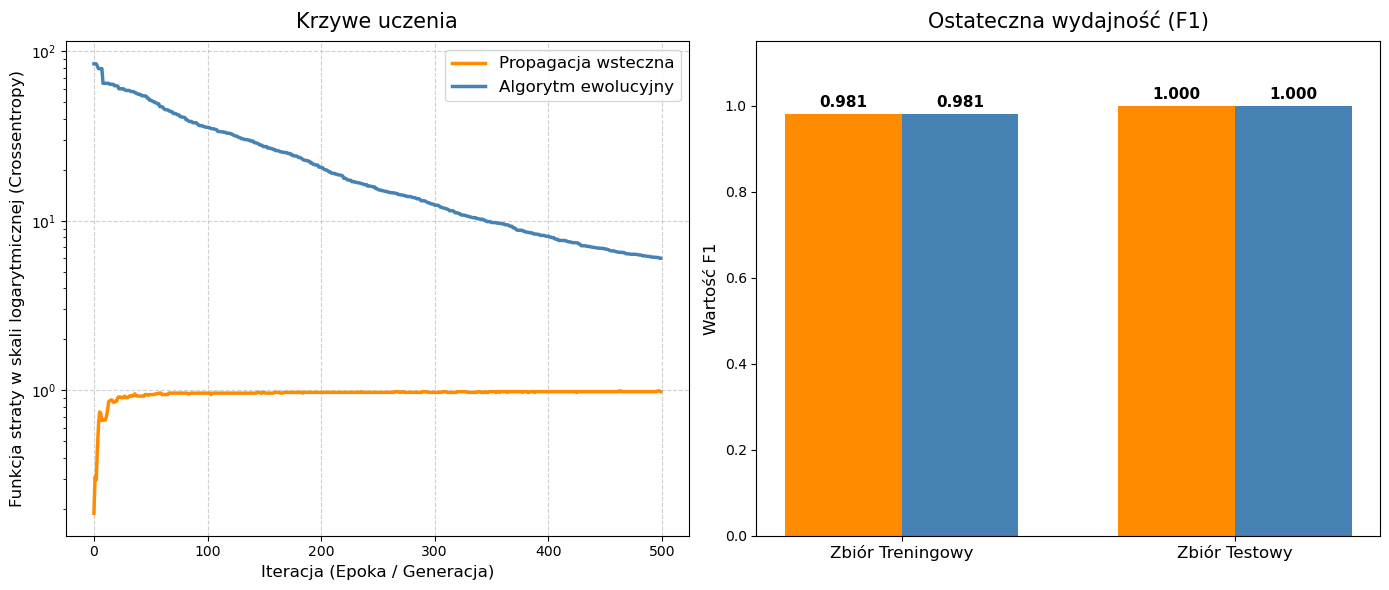

In [429]:
porownaj_modele(hist_strata_bp, hist_best_ea, f1_treningowe_bp, f1_testowe_bp, f1_treningowe_ea, f1_testowe_ea, metryka="F1")

# Auto-mpg

In [430]:
url = "http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 
                'acceleration', 'model_year', 'origin', 'car_name']
autompg = pd.read_csv(url, names=column_names, sep=r'\s+', na_values='?')
autompg = autompg.dropna()

X = autompg.drop(columns=['mpg', 'car_name']).to_numpy()
y = autompg['mpg'].to_numpy().reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=123)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.2, random_state=123)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [431]:
warstwy = [
    warstwa_liniowa(7, 16, inicjalizacja='he'),
    tanh(),
    warstwa_liniowa(16, 1, inicjalizacja='he'),
    liniowa()
]
model_ea = MLP(warstwy, learning_rate=0.01, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
model_bp = MLP(copy.deepcopy(warstwy), learning_rate=0.01, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)

poczatkowy_chromosom = model_chromosom(model_ea)
dlugosc_chromosomu = len(poczatkowy_chromosom)

print("------ Algorytm ewolucyjny ------")

print(f"Ilość optymalizowanych wag (długość chromosomu): {dlugosc_chromosomu}")

loss_fn = MSE()

fitness_func = lambda chrom: mlp_fitness(chrom, model=model_ea, X_train=X_train_scaled, y_train=y_train, funkcja_straty=loss_fn)

# TRENOWANIE ALGORYTMEM EWOLUCYJNYM
ea = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=gaussian_mutation,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection,
    pop_size=100, 
    chromosome_length=dlugosc_chromosomu,
    crossover_prob=0.8,
    mutation_prob=0.3
)

best_chrom, best_loss, hist_best_ea, hist_all = ea.train(generations=500)

chromosom_model(model_ea, best_chrom)
print(f"Najlepsza strata (MSE) z EA: {best_loss:.4f}")

y_pred_ea_train = model_ea.forward(X_train_scaled)
mse_treningowe_ea = mse(y_train, y_pred_ea_train)
print(f"MSE treningowe FINALNE: {mse_treningowe_ea:.4f}")

y_pred_ea_test = model_ea.forward(X_test_scaled)
mse_testowe_ea = mse(y_test, y_pred_ea_test)
print(f"MSE testowe FINALNE: {mse_testowe_ea:.4f}")

print("\n------ Propagacja wsteczna ------")

# TRENOWANIE BACKPROPAGATION (PROPAGACJĄ WSTECZNĄ)
hist_strata_bp, _, mse_treningowe_bp, mse_testowe_bp = train(
    X_train, y_train, X_test, y_test, X_val, y_val, 
    model=model_bp, 
    epoki=500, 
    rozmiar_batcha=32, 
    funkcja_straty=MSE, 
    regresja=True,
    patience=1000
)

------ Algorytm ewolucyjny ------
Ilość optymalizowanych wag (długość chromosomu): 145


100%|██████████| 500/500 [00:03<00:00, 135.96it/s]


Najlepsza strata (MSE) z EA: 9.2527
MSE treningowe FINALNE: 9.2527
MSE testowe FINALNE: 7.2226

------ Propagacja wsteczna ------


100%|██████████| 500/500 [00:00<00:00, 1533.20it/s]

Wczytano wagi z najlepszej epoki 499 (Strata Walidacyjna: 0.0072).
MSE treningowe FINALNE: 7.4458
MSE testowe FINALNE: 5.9874


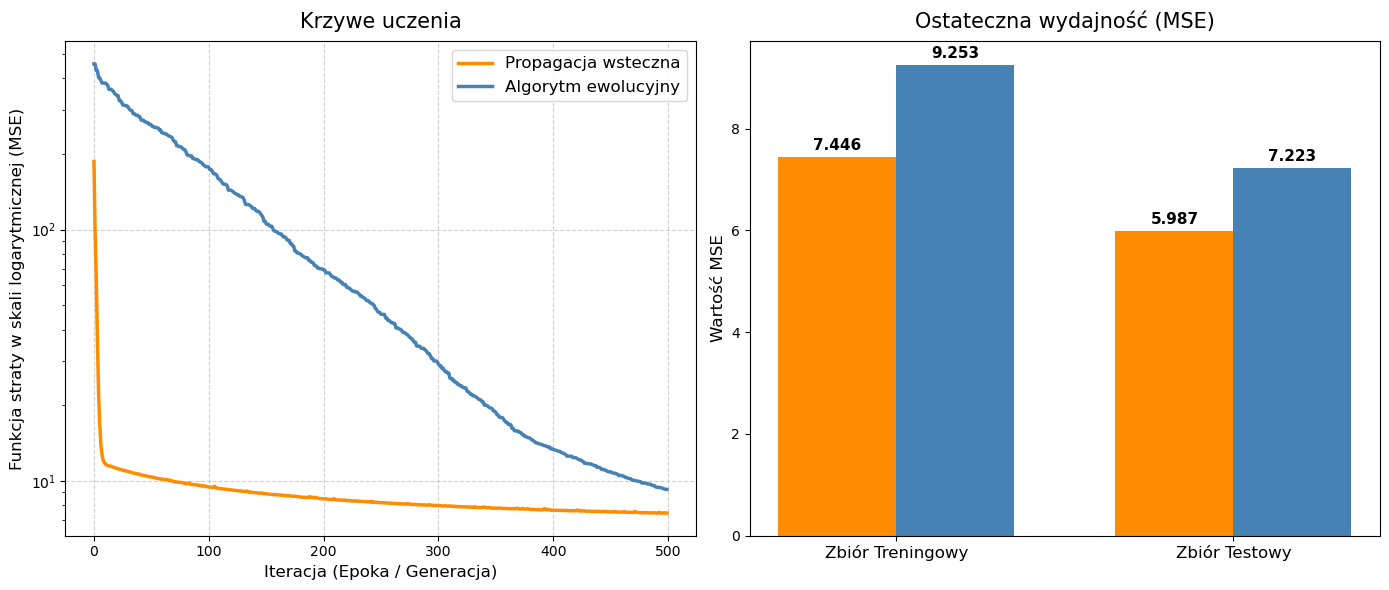

In [432]:
porownaj_modele(hist_strata_bp, hist_best_ea, mse_treningowe_bp, mse_testowe_bp, mse_treningowe_ea, mse_testowe_ea, metryka="MSE")

# Multimodal large

In [433]:
multimodal_large_test = pd.read_csv("mio1/regression/multimodal-large-test.csv")
multimodal_large_train = pd.read_csv("mio1/regression/multimodal-large-training.csv")

X_train = multimodal_large_train[['x']].to_numpy()
y_train = multimodal_large_train[['y']].to_numpy()
X_test = multimodal_large_test[['x']].to_numpy()
y_test = multimodal_large_test[['y']].to_numpy()

X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.2, random_state=123)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

y_scaler = MinMaxScaler()
y_train_scaled = y_scaler.fit_transform(y_train)
y_val_scaled = y_scaler.transform(y_val)
y_test_scaled = y_scaler.transform(y_test)

In [434]:
warstwy = [
    warstwa_liniowa(1, 16, inicjalizacja='he'),
    tanh(),
    warstwa_liniowa(16, 16, inicjalizacja='he'),
    tanh(),
    warstwa_liniowa(16, 1, inicjalizacja='he'),
    liniowa()
]
model_ea = MLP(warstwy, learning_rate=0.01, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)
model_bp = MLP(copy.deepcopy(warstwy), learning_rate=0.01, optymalizacja='moment', wspolczynnik=0.9, l2_lambda=0)

poczatkowy_chromosom = model_chromosom(model_ea)
dlugosc_chromosomu = len(poczatkowy_chromosom)

print("------ Algorytm ewolucyjny ------")

print(f"Ilość optymalizowanych wag (długość chromosomu): {dlugosc_chromosomu}")

loss_fn = MSE()

fitness_func = lambda chrom: mlp_fitness(chrom, model=model_ea, X_train=X_train_scaled, y_train=y_train_scaled, funkcja_straty=loss_fn)
mut_func = lambda ind: gaussian_mutation(ind, mutation_rate=0.05, sigma=0.2)
mocny_turniej = partial(tournament_selection, k=5)

# TRENOWANIE ALGORYTMEM EWOLUCYJNYM
ea = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=mocny_turniej,
    pop_size=100, 
    chromosome_length=dlugosc_chromosomu,
    crossover_prob=0.8,
    mutation_prob=0.5
)

best_chrom, best_loss, hist_best_ea, hist_all = ea.train(generations=3000)

chromosom_model(model_ea, best_chrom)
print(f"Najlepsza strata (MSE) z EA: {best_loss:.4f}")

y_pred_ea_train = model_ea.forward(X_train_scaled)
y_pred_ea_train_prawdziwe = y_scaler.inverse_transform(y_pred_ea_train)
mse_treningowe_ea = mse(y_train, y_pred_ea_train_prawdziwe)
print(f"MSE treningowe FINALNE: {mse_treningowe_ea:.4f}")

y_pred_ea_test = model_ea.forward(X_test_scaled)
y_pred_ea_test_prawdziwe = y_scaler.inverse_transform(y_pred_ea_test)
mse_testowe_ea = mse(y_test, y_pred_ea_test_prawdziwe)
print(f"MSE testowe FINALNE: {mse_testowe_ea:.4f}")

print("\n------ Propagacja wsteczna ------")

# TRENOWANIE BACKPROPAGATION (PROPAGACJĄ WSTECZNĄ)
hist_strata_bp, _, mse_treningowe_bp, mse_testowe_bp = train(
    X_train, y_train, X_test, y_test, X_val, y_val, 
    model=model_bp, 
    epoki=3000, 
    rozmiar_batcha=32, 
    funkcja_straty=MSE, 
    regresja=True,
    patience=1000
)

------ Algorytm ewolucyjny ------
Ilość optymalizowanych wag (długość chromosomu): 321


100%|██████████| 3000/3000 [20:53<00:00,  2.39it/s]


Najlepsza strata (MSE) z EA: 0.0269
MSE treningowe FINALNE: 1069.1417
MSE testowe FINALNE: 1059.4160

------ Propagacja wsteczna ------


100%|██████████| 3000/3000 [01:33<00:00, 31.94it/s]

Wczytano wagi z najlepszej epoki 2999 (Strata Walidacyjna: 0.0001).
MSE treningowe FINALNE: 11.3312
MSE testowe FINALNE: 6.8526


In [435]:
y_min = y_scaler.data_min_[0]
y_max = y_scaler.data_max_[0]
roznica_y_kwadrat = (y_max - y_min) ** 2

hist_best_ea_prawdziwe = [blad * roznica_y_kwadrat for blad in hist_best_ea]

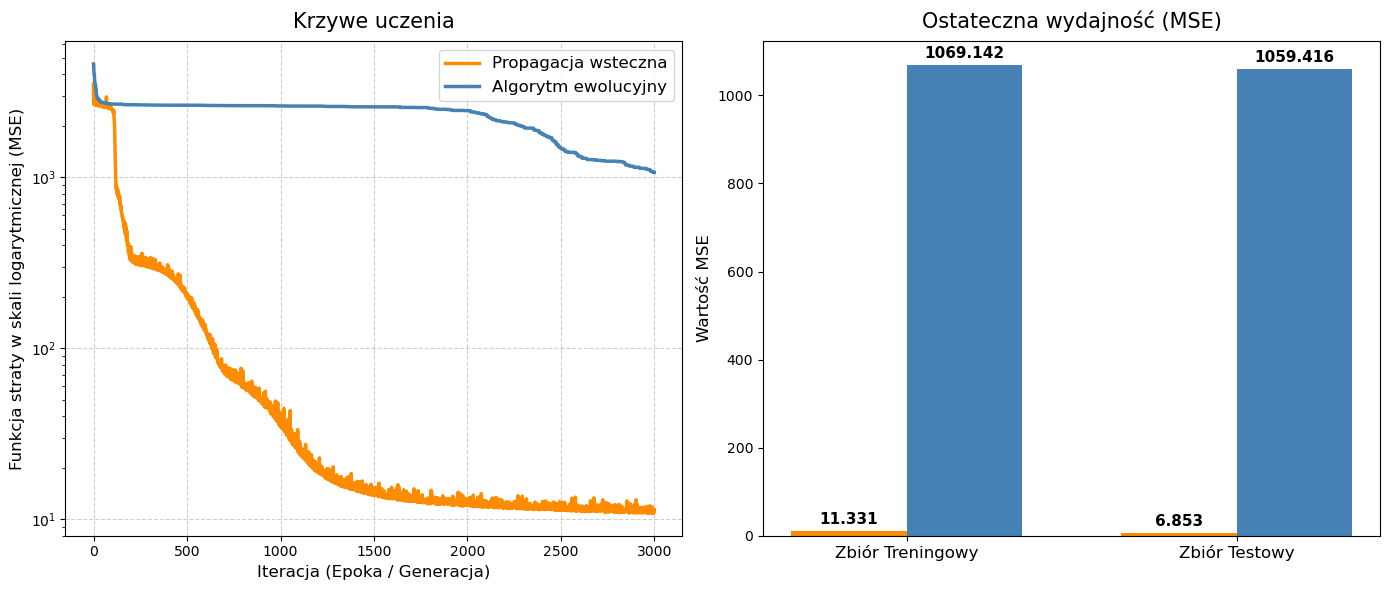

In [436]:
porownaj_modele(hist_strata_bp, hist_best_ea_prawdziwe, mse_treningowe_bp, mse_testowe_bp, mse_treningowe_ea, mse_testowe_ea, metryka="MSE")